In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

In [2]:
import os
import json
import random
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils, env_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4,5,6,7")

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
logging_utils.configure(level=logging.INFO)

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_SHORT = MODEL_NAME.split("/")[-1]
VERSION = "conditions"
CACHE_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", VERSION, MODEL_SHORT)

mt = ModelandTokenizer(
    model_key=MODEL_NAME, dtype=torch.bfloat16, device_map="auto", attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}")

2026-06-11 16:02:15 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-11 16:02:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-11 16:02:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-11 16:02:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-11 16:02:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-11 16:02:16 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-11 16:02:38 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-11 16:02:38 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-11 16:02:38 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120


In [4]:
from src.goals.functional import apply_chat_template, supports_chat_template
from src.functional import generate_with_patch

test_samples = [
    {
        "task": "Write a C++ function that checks if a string is a palindrome.",
        "correct": """bool isPalindrome(string s){
    int left = 0, right = s.size() - 1;
    while (left < right) {
        if (s[left] != s[right]) return false;
        left++;
        right--;
    }
    return true;
}""",
        "incorrect": """bool isPalindrome(string s){
    return s == s[::-1];
}""",
    },
    {
        "task": "Write a Python function `factorial(n)` that returns n! using recursion.",
        "correct": """def factorial(n):
    if n == 0:
        return 1
    else:
        return n * factorial(n - 1)""",
        "incorrect": """def factorial(n):
    result = 0
    for i in range(1, n + 1):
        result *= i
    return result""",
    },
    {
        "task": "Write a Python function `is_even(n)` returning True iff n is even.",
        "correct": """def is_even(n):
    return n % 2 == 0""",
        "incorrect": """def is_even(n):
    return n % 2 == 5""",
    },
    {
        "task": "Write a Python function `n_pos(lst)` returning how many elements are positive.",
        "correct": """def n_pos(lst):
    return sum(1 for x in lst if x > 0)""",
        "incorrect": """def n_pos(lst):
    return sum(1 for x in lst if x == 4)""",
    },
    {
        "task": "Write a Python function `factorial(n)` returning n!.",
        "correct": "def factorial(n):\n    result = 1\n    for i in range(1, n + 1):\n        result *= i\n    return result",
        "incorrect": "def factorial(n):\n    return n + 1",
    },
    {
        "task": "Write a Python function `count_vowels(s)` returning the number of vowels in s.",
        "correct": "def count_vowels(s):\n    return sum(c in 'aeiouAEIOU' for c in s)",
        "incorrect": "def count_vowels(s):\n    return s.count(' ')",
    },
]


def build_prompt(task, code):
    system_instruction = """You are a helpful assistant proficient in coding. Provide clean and concise code solutions to the user's task. Put your code inside <code> </code> tags. Do not include any explations or comments."""
    messages = [
        {
            "role": "system",
            "content": system_instruction,
        },
        {
            "role": "user",
            "content": f"{task}",
        },
        {
            "role": "assistant",
            "content": f"<code>\n{code}\n</",
        },
    ]
    if supports_chat_template(mt):
        return mt.tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=False,  # Don't add a new assistant header
            continue_final_message=True,  # Don't close the assistant turn with <|eot_id|>
            tokenize=False,
            chat_template_kwargs={"enable_thinking": False},  # only Qwen3 and Qwen3.5
        )
    else:
        return f"""Instruction: {system_instruction}
Task: {task}
Answer:
<code>\n{code}"""


test_sample = test_samples[-1]
test_prompt = build_prompt(test_sample["task"], test_sample["incorrect"])
test_prompt += "code>\n\n(correct vs incorrect) The code is:"

test_gen = generate_with_patch(
    mt=mt,
    inputs=test_prompt,
    max_new_tokens=128,
    do_sample=False,
    remove_prefix=True,
    n_gen_per_prompt=1,
)[0]

rich_print(f"[white]{test_prompt}[white][sea_green1]{test_gen}[sea_green1]")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


<|im_start|>system
You are a helpful assistant proficient in coding. Provide clean and concise code solutions to the user's task. Put 
your code inside <code> </code> tags. Do not include any explations or comments.<|im_end|>
<|im_start|>user
Write a Python function `count_vowels(s)` returning the number of vowels in s.<|im_end|>
<|im_start|>assistant
<code>
def count_vowels(s):
    return s.count(' ')
</code>

(correct vs incorrect) The code is: incorrect

Here is the correct version:

<code>
def count_vowels(s):
    vowels = 'aeiouAEIOU'
    return sum(1 for char in s if char in vowels)
</code>

## 1. Behavioral trait — does a flawed stub make the LM keep generating?

Prefill with task + `<code>\n{stub}\n</` for a **correct** and a **flawed** implementation, across two locked error types (`N_PER_FILE` each):

- **wrong_task** — the stub is complete and runs but does something *unrelated* to the task (e.g. "is palindrome?" → checks if the first char is lowercase).
- **incomplete** — the stub is on-task and syntactically complete (parses, runs, no mid-line cut-off) but doesn't finish: misses required conditions (prime by only 2 & 3) or stops after partial steps.

The trailing `</` nudges a close, so a *satisfied* model stops; an *unsatisfied* one keeps generating. Greedy, batched. **Hypothesis:** correct → stop; wrong_task / incomplete → re-attempt.

In [5]:
import json
from collections import Counter
from src.tokens import prepare_input

### ---- generation config ----
DATASET_FILES  = ["wrong_task.json", "incomplete.json"]   # error-type files to compare
N_PER_FILE     = 10        # cap per file (None = all)
MAX_NEW_TOKENS = 512
BATCH_SIZE     = 16
### ----------------------------

STUBS = []
for _fn in DATASET_FILES:
    with open(os.path.join("..", "..", "data", "verifier", _fn)) as f:
        _items = json.load(f)
    _items = _items[:N_PER_FILE] if N_PER_FILE is not None else _items
    for s in _items:
        s["etype"] = _fn[:-5]                       # strip ".json"
        s["uid"] = f"{s['etype']}/{s['id']}"
    STUBS.extend(_items)
print(f"loaded {len(STUBS)} tasks: {dict(Counter(s['etype'] for s in STUBS))}")

# one row per (task, kind): prefilled with `<code>\n{stub}\n</` and continues
gen_rows = []
for s in STUBS:
    for kind in ("correct", "incorrect"):
        gen_rows.append(dict(id=s["uid"], etype=s["etype"], lang=s["lang"], bug=s["bug"],
                             kind=kind, task=s["task"], prompt=build_prompt(s["task"], s[kind])))


@torch.no_grad()
def batched_generate(prompts, batch_size=BATCH_SIZE, max_new_tokens=MAX_NEW_TOKENS):
    outs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc="generate"):
        inp = prepare_input(prompts=prompts[i:i + batch_size], tokenizer=mt)
        outs.extend(generate_with_patch(mt=mt, inputs=inp, max_new_tokens=max_new_tokens,
                                        do_sample=False, remove_prefix=True))
    return outs


gens = batched_generate([r["prompt"] for r in gen_rows])
for r, g in zip(gen_rows, gens):
    r["gen"] = g
print(f"generated {len(gens)} continuations  (max_new_tokens={MAX_NEW_TOKENS})")

loaded 20 tasks: {'wrong_task': 10, 'incomplete': 10}


generate:   0%|          | 0/3 [00:00<?, ?it/s]

generated 40 continuations  (max_new_tokens=512)


## 2. Cheap behavioral evaluator

Heuristics on the **full block** (`<code>` + stub + continuation — the LM doesn't reliably re-emit `</code>` between attempts): continuation token length, clean-stop (`</code>` then <5 chars), and a *re-attempt* flag = a **second** `<code>`/`</code>` tag, a **second function definition** (`n_defs ≥ 2`, language-aware), or a function signature after the first close. Compared correct-vs-incorrect overall, split by bug severity, and paired within task.

=== correct vs incorrect ===
            n  median_gen  mean_gen  stopped_clean  reattempt  mean_n_defs  mean_n_close
kind                                                                                    
correct    20       2.000     2.000          1.000      0.000        1.000         1.000
incorrect  20      30.000    23.350          0.400      0.600        1.600         1.600

=== incorrect, by error type ===
             n  median_gen  stopped_clean  reattempt  mean_n_defs
etype                                                            
incomplete  10       2.000          0.600      0.400        1.400
wrong_task  10      34.500          0.200      0.800        1.800

within-task: incorrect longer than correct in 60.0% of tasks  (median delta = 28 tokens)


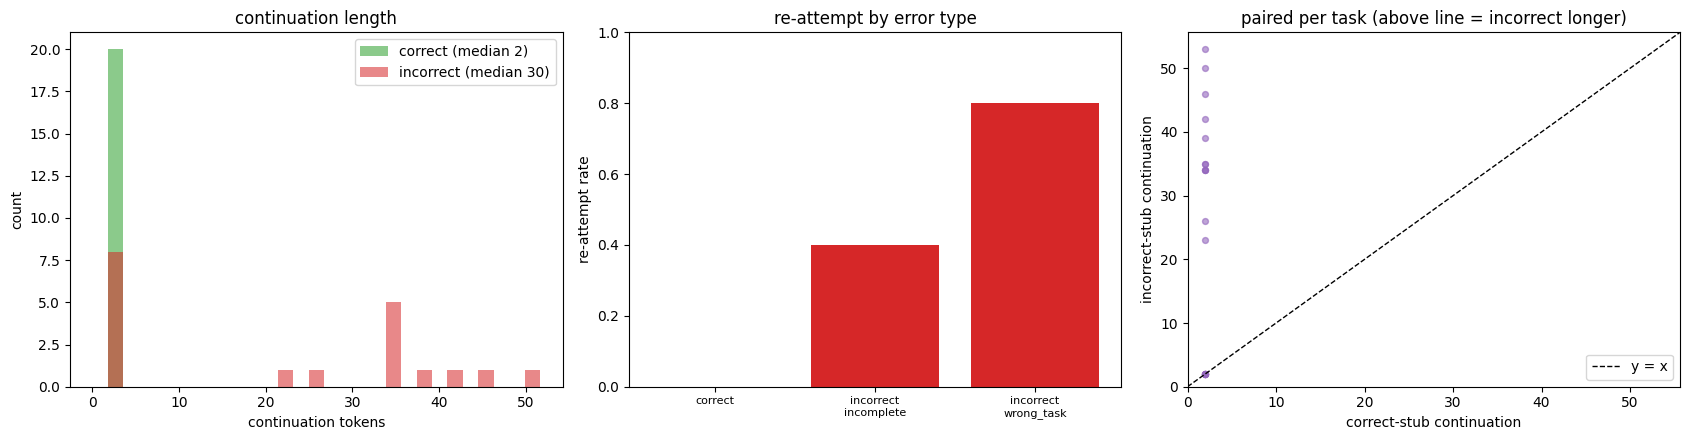

In [6]:
import re

CLOSE, OPEN = "</code>", "<code>"
_SIG = re.compile(r"(def |#include|\bbool |\bint |\blong |\bstring |\bvoid |\bdouble |\bchar )")
_PY_DEF  = re.compile(r"(?m)^[ \t]*def\s+\w+\s*\(")
_CPP_DEF = re.compile(r"(?m)^[ \t]*(?:unsigned\s+)?(?:int|long|short|bool|string|void|double|float|char|auto)"
                      r"[ \t&*]+\w+\s*\([^;]*\)\s*\{")


def full_code(r):
    """Stub (from the prompt, from the assistant `<code>`) + the continuation. The LM doesn't
    reliably re-emit `</code>` between attempts, so we always analyze the whole block."""
    return r["prompt"][r["prompt"].index("<code>\n"):] + r["gen"]


def analyze(code, lang="python"):
    """Cheap stop-vs-keep-trying heuristics on the FULL block (opening <code> + stub + continuation).
    The first <code>/</code> are the *given* ones, so a reopen = a SECOND tag / function def."""
    i = code.find(CLOSE)
    closed = i != -1
    tail = code[i + len(CLOSE):] if closed else ""       # after the first close = retry material
    tail_code = tail.strip()
    n_close = code.count(CLOSE)
    n_open  = code.count(OPEN)                            # 1 = given opening; >=2 = reopened block
    n_defs  = len((_PY_DEF if lang == "python" else _CPP_DEF).findall(code))
    reattempt = (n_open >= 2) or (n_close >= 2) or (n_defs >= 2) or (closed and bool(_SIG.search(tail_code)))
    stopped_clean = closed and len(tail_code) < 5        # closed once, ~nothing after
    return dict(n_tok=len(mt.tokenizer(code, add_special_tokens=False).input_ids),
                chars=len(code), closed=closed, n_close=n_close, n_open=n_open, n_defs=n_defs,
                stopped_clean=stopped_clean, reattempt=reattempt, tail_len=len(tail_code))


df = pd.DataFrame([
    {**{k: r[k] for k in ("id", "etype", "lang", "bug", "kind")},
     "gen_tok": len(mt.tokenizer(r["gen"], add_special_tokens=False).input_ids),
     **analyze(full_code(r), r["lang"])}
    for r in gen_rows
])

agg = df.groupby("kind").agg(
    n=("id", "size"), median_gen=("gen_tok", "median"), mean_gen=("gen_tok", "mean"),
    stopped_clean=("stopped_clean", "mean"), reattempt=("reattempt", "mean"),
    mean_n_defs=("n_defs", "mean"), mean_n_close=("n_close", "mean"),
).reindex(["correct", "incorrect"])
print("=== correct vs incorrect ===")
print(agg.to_string(float_format=lambda v: f"{v:.3f}"))

print("\n=== incorrect, by error type ===")
print(df[df.kind == "incorrect"].groupby("etype").agg(
    n=("id", "size"), median_gen=("gen_tok", "median"), stopped_clean=("stopped_clean", "mean"),
    reattempt=("reattempt", "mean"), mean_n_defs=("n_defs", "mean"),
).to_string(float_format=lambda v: f"{v:.3f}"))

piv = df.pivot_table(index="id", columns="kind", values="gen_tok")
print(f"\nwithin-task: incorrect longer than correct in {(piv['incorrect'] - piv['correct'] > 0).mean():.1%} "
      f"of tasks  (median delta = {(piv['incorrect'] - piv['correct']).median():.0f} tokens)")

# ---- plots ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
COL = {"correct": "tab:green", "incorrect": "tab:red"}

bins = np.linspace(0, df["gen_tok"].quantile(0.98) + 1, 30)
for kind in ("correct", "incorrect"):
    v = df[df.kind == kind]["gen_tok"]
    axes[0].hist(v, bins=bins, alpha=0.55, color=COL[kind], label=f"{kind} (median {v.median():.0f})")
axes[0].set_xlabel("continuation tokens"); axes[0].set_ylabel("count")
axes[0].set_title("continuation length"); axes[0].legend()

# re-attempt rate: correct baseline vs each incorrect error type
cats = [("correct", "tab:green", df[df.kind == "correct"]["reattempt"].mean())]
for et in sorted(df["etype"].unique()):
    cats.append((f"incorrect\n{et}", "tab:red",
                 df[(df.kind == "incorrect") & (df.etype == et)]["reattempt"].mean()))
axes[1].bar(range(len(cats)), [c[2] for c in cats], color=[c[1] for c in cats])
axes[1].set_xticks(range(len(cats))); axes[1].set_xticklabels([c[0] for c in cats], fontsize=8)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("re-attempt rate"); axes[1].set_title("re-attempt by error type")

axes[2].scatter(piv["correct"], piv["incorrect"], s=18, alpha=0.6, color="tab:purple")
lim = [0, max(piv["correct"].max(), piv["incorrect"].max()) * 1.05]
axes[2].plot(lim, lim, "k--", lw=1, label="y = x")
axes[2].set_xlim(lim); axes[2].set_ylim(lim)
axes[2].set_xlabel("correct-stub continuation"); axes[2].set_ylabel("incorrect-stub continuation")
axes[2].set_title("paired per task (above line = incorrect longer)"); axes[2].legend()
plt.tight_layout(); plt.show()

In [7]:
# qualitative — a correct stub (stops) vs the matching incorrect stub (keeps trying)
def _gtok(s): return len(mt.tokenizer(s, add_special_tokens=False).input_ids)

def _show(row):
    a = analyze(full_code(row), row["lang"])
    rich_print(f"[bold]{row['id']} · {row['kind']} · bug={row['bug']}[/bold]  "
               f"(gen_tok={_gtok(row['gen'])}, stopped_clean={a['stopped_clean']}, "
               f"reattempt={a['reattempt']}, n_defs={a['n_defs']})")
    rich_print(f"[grey58]{row['task']}[/grey58]")
    rich_print(f"[sea_green1]{full_code(row)}[/sea_green1]\n")

_reatt = [r["id"] for r in gen_rows
          if (
                r["kind"] == "incorrect" 
                and not analyze(full_code(r), r["lang"])["reattempt"]
                and r["bug"] == "incomplete"
            )]

print(f"Filtered to {len(_reatt)} samples")
ex = _reatt[1] if _reatt else gen_rows[0]["id"]

_show(next(r for r in gen_rows if r["id"] == ex and r["kind"] == "correct"))
_show(next(r for r in gen_rows if r["id"] == ex and r["kind"] == "incorrect"))

Filtered to 6 samples


incomplete/python_001 · correct · bug=incomplete  (gen_tok=2, stopped_clean=True, reattempt=False, n_defs=1)

Write a Python function `fizzbuzz(n)` returning 'FizzBuzz' if n is divisible by 15, else 'Fizz' for 3, 'Buzz' for 
5, else str(n).

<code>
def fizzbuzz(n):
    if n % 15 == 0:
        return 'FizzBuzz'
    if n % 3 == 0:
        return 'Fizz'
    if n % 5 == 0:
        return 'Buzz'
    return str(n)
</code>

incomplete/python_001 · incorrect · bug=incomplete  (gen_tok=2, stopped_clean=True, reattempt=False, n_defs=1)

Write a Python function `fizzbuzz(n)` returning 'FizzBuzz' if n is divisible by 15, else 'Fizz' for 3, 'Buzz' for 
5, else str(n).

<code>
def fizzbuzz(n):
    if n % 3 == 0:
        return 'Fizz'
    if n % 5 == 0:
        return 'Buzz'
    return str(n)
</code>

In [8]:
res = next(r for r in gen_rows if r["id"] == ex and r["kind"] == "correct")
print(analyze(res['prompt'][res['prompt'].index("<code>\n") : ] + res["gen"]))
res

{'n_tok': 63, 'chars': 177, 'closed': True, 'n_close': 1, 'n_open': 1, 'n_defs': 1, 'stopped_clean': True, 'reattempt': False, 'tail_len': 0}


{'id': 'incomplete/python_001',
 'etype': 'incomplete',
 'lang': 'python',
 'bug': 'incomplete',
 'kind': 'correct',
 'task': "Write a Python function `fizzbuzz(n)` returning 'FizzBuzz' if n is divisible by 15, else 'Fizz' for 3, 'Buzz' for 5, else str(n).",
 'prompt': "<|im_start|>system\nYou are a helpful assistant proficient in coding. Provide clean and concise code solutions to the user's task. Put your code inside <code> </code> tags. Do not include any explations or comments.<|im_end|>\n<|im_start|>user\nWrite a Python function `fizzbuzz(n)` returning 'FizzBuzz' if n is divisible by 15, else 'Fizz' for 3, 'Buzz' for 5, else str(n).<|im_end|>\n<|im_start|>assistant\n<code>\ndef fizzbuzz(n):\n    if n % 15 == 0:\n        return 'FizzBuzz'\n    if n % 3 == 0:\n        return 'Fizz'\n    if n % 5 == 0:\n        return 'Buzz'\n    return str(n)\n</",
 'gen': 'code>'}

## 4. Detection — can the LM verbalize correct vs incorrect?

The stop/continue behavior is noisy, so first check whether the model can even *tell* the code is flawed. Close the block and ask: append `DETECT_SUFFIX = "code>\n\n(correct vs incorrect) The code is:"` to each stub prompt (recall `build_prompt` ends in `\n</`, so `code>` completes `</code>`), then compare the next-token probability of ` correct` vs ` incorrect` (both single tokens — 4396 / 15114). Predict *incorrect* iff `P( incorrect) > P( correct)`; a good verifier calls the correct stub "correct" and the flawed ones "incorrect". Reported overall, by error type, with the score distribution. This is a prerequisite for a hidden verifier probe — if the model can't verbalize it, the latent signal is likely weak.

=== verbalized detection  (P(' correct') vs P(' incorrect')) ===
overall accuracy: 100.0%  (n=40)
  correct   stubs called 'correct'  : 100.0%
  incorrect stubs called 'incorrect': 100.0%

incorrect detection rate by error type:
etype
incomplete   1.000
wrong_task   1.000

mean score_incorrect:  correct=0.009   incorrect=0.999


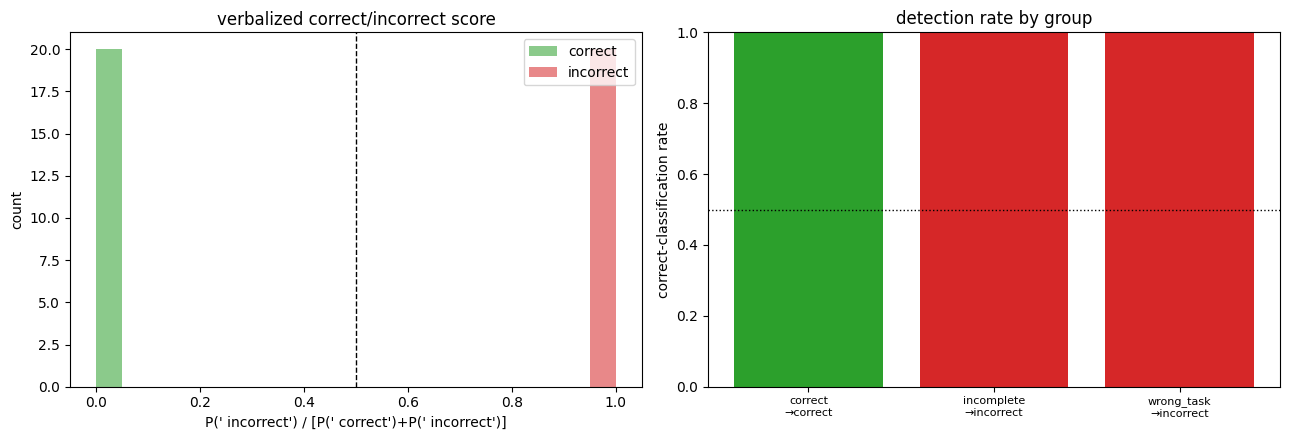

In [9]:
from src.functional import predict_next_token

### ---- detection config ----
DETECT_SUFFIX = "code>\n\n(correct vs incorrect) The code is:"   # closes </code>, then asks
### ---------------------------
ID_CORRECT   = mt.tokenizer(" correct",   add_special_tokens=False).input_ids[0]
ID_INCORRECT = mt.tokenizer(" incorrect", add_special_tokens=False).input_ids[0]

det_prompts = [r["prompt"] + DETECT_SUFFIX for r in gen_rows]
toi = [[ID_CORRECT, ID_INCORRECT]] * len(det_prompts)
_, tracked = predict_next_token(mt, det_prompts, k=5, token_of_interest=toi, batch_size=BATCH_SIZE)

det = pd.DataFrame([
    dict(id=r["id"], etype=r["etype"], kind=r["kind"],
         p_correct=tr[ID_CORRECT][1].prob, p_incorrect=tr[ID_INCORRECT][1].prob)
    for r, tr in zip(gen_rows, tracked)
])
det["score_incorrect"] = det["p_incorrect"] / (det["p_correct"] + det["p_incorrect"] + 1e-12)
det["pred_incorrect"] = det["p_incorrect"] > det["p_correct"]
det["hit"] = det["pred_incorrect"] == (det["kind"] == "incorrect")

cor, inc = det[det.kind == "correct"], det[det.kind == "incorrect"]
print("=== verbalized detection  (P(' correct') vs P(' incorrect')) ===")
print(f"overall accuracy: {det['hit'].mean():.1%}  (n={len(det)})")
print(f"  correct   stubs called 'correct'  : {(~cor['pred_incorrect']).mean():.1%}")
print(f"  incorrect stubs called 'incorrect': {inc['pred_incorrect'].mean():.1%}")
print("\nincorrect detection rate by error type:")
print(inc.groupby('etype')['pred_incorrect'].mean().to_string(float_format=lambda v: f'{v:.3f}'))
print("\nmean score_incorrect:  correct={:.3f}   incorrect={:.3f}".format(
    cor['score_incorrect'].mean(), inc['score_incorrect'].mean()))

# ---- plots ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for kind, col in [("correct", "tab:green"), ("incorrect", "tab:red")]:
    axes[0].hist(det[det.kind == kind]["score_incorrect"], bins=np.linspace(0, 1, 21),
                 alpha=0.55, color=col, label=kind)
axes[0].axvline(0.5, color="k", ls="--", lw=1)
axes[0].set_xlabel("P(' incorrect') / [P(' correct')+P(' incorrect')]"); axes[0].set_ylabel("count")
axes[0].set_title("verbalized correct/incorrect score"); axes[0].legend()

cats = [("correct\n\u2192correct", "tab:green", (~cor['pred_incorrect']).mean())]
for et in sorted(inc["etype"].unique()):
    cats.append((f"{et}\n\u2192incorrect", "tab:red", inc[inc.etype == et]['pred_incorrect'].mean()))
axes[1].bar(range(len(cats)), [c[2] for c in cats], color=[c[1] for c in cats])
axes[1].set_xticks(range(len(cats))); axes[1].set_xticklabels([c[0] for c in cats], fontsize=8)
axes[1].set_ylim(0, 1); axes[1].axhline(0.5, color="k", ls=":", lw=1)
axes[1].set_ylabel("correct-classification rate"); axes[1].set_title("detection rate by group")
plt.tight_layout(); plt.show()

## 5. Verifier probe — contrastive direction at the `":"` position

Read the latent at the **last token** (`":"` of the detection suffix) — the position whose logits decode to ` correct`/` incorrect`. Because that token is *identical* for both classes, token-identity is automatically controlled (no demeaning needed). Pooled contrast: **D+ = incorrect** (wrong_task + incomplete), **D- = correct**. Train a hinge direction + a mean-diff baseline, split by task (no leakage), sweep layers, and report held-out accuracy + per-error-type generalization. Self-contained: reads the JSON datasets directly (no need to run §1's generation).

In [10]:
from src.functional import get_hs
from src.tokens import prepare_input

### ---- probe config ----
PROBE_FILES  = ["wrong_task.json", "incomplete.json"]
PROBE_N      = None        # per-file cap (None = all)
PROBE_SUFFIX = globals().get("DETECT_SUFFIX", "code>\n\n(correct vs incorrect) The code is:")
PROBE_LAYERS = sorted(set(range(0, mt.n_layer, 4)) | {mt.n_layer - 1})
LAYER_KEYS   = ["emb"] + PROBE_LAYERS
PROBE_BS     = 16
### -----------------------
def _lname(L): return mt.embedder_name if L == "emb" else mt.layer_names[L]
def _lx(L): return -1 if L == "emb" else L
def _llab(L): return "emb" if L == "emb" else str(L)

_stubs = []
for _fn in PROBE_FILES:
    with open(os.path.join("..", "..", "data", "verifier", _fn)) as f:
        _it = json.load(f)
    _it = _it[:PROBE_N] if PROBE_N else _it
    for s in _it:
        s["etype"] = _fn[:-5]
    _stubs.extend(_it)

def _vp(task, code): return build_prompt(task, code) + PROBE_SUFFIX

pos_rows = [dict(etype=s["etype"], task=s["task"], prompt=_vp(s["task"], s["incorrect"])) for s in _stubs]
_seen, neg_rows = set(), []
for s in _stubs:                                  # dedup corrects (shared across both files)
    p = _vp(s["task"], s["correct"])
    if p not in _seen:
        _seen.add(p); neg_rows.append(dict(etype=s["etype"], task=s["task"], prompt=p))
probe_rows = pos_rows + neg_rows
labels = np.array([1] * len(pos_rows) + [0] * len(neg_rows))   # 1=incorrect(D+), 0=correct(D-)
etypes = np.array([r["etype"] for r in probe_rows])
tasks  = np.array([r["task"] for r in probe_rows])
print(f"probe rows: {len(pos_rows)} incorrect(+)  {len(neg_rows)} correct(-)  "
      f"| etypes {dict(pd.Series([r['etype'] for r in pos_rows]).value_counts())}")


@torch.no_grad()
def cache_probe_hs(rows, batch_size=PROBE_BS):
    names = [_lname(L) for L in LAYER_KEYS]
    out = [None] * len(rows)
    for i0 in tqdm(range(0, len(rows), batch_size), desc="probe hs"):
        chunk = rows[i0:i0 + batch_size]
        inp = prepare_input(prompts=[r["prompt"] for r in chunk], tokenizer=mt)
        hs = get_hs(mt, inp, locations=[(ly, -1) for ly in names], return_dict=True)
        for L, ly in zip(LAYER_KEYS, names):
            v = hs[(ly, -1)]
            if v.ndim == 1: v = v.unsqueeze(0)
            for bi in range(len(chunk)):
                if out[i0 + bi] is None: out[i0 + bi] = {}
                out[i0 + bi][L] = v[bi].detach().to("cpu", dtype=torch.float16)
    return out


probe_hs = cache_probe_hs(probe_rows)
print(f"cached HS at ':' for {len(probe_rows)} rows x {len(LAYER_KEYS)} layers")

probe rows: 442 incorrect(+)  254 correct(-)  | etypes {'wrong_task': np.int64(224), 'incomplete': np.int64(218)}


probe hs:   0%|          | 0/44 [00:00<?, ?it/s]

cached HS at ':' for 696 rows x 18 layers


train +359/-204   test +83/-50  (50/254 tasks held out)
layer=emb  acc_hinge=0.500  acc_md=0.500
layer=  0  acc_hinge=0.637  acc_md=0.609
layer=  4  acc_hinge=0.683  acc_md=0.673
layer=  8  acc_hinge=0.689  acc_md=0.689
layer= 12  acc_hinge=0.695  acc_md=0.717
layer= 16  acc_hinge=0.667  acc_md=0.679
layer= 20  acc_hinge=0.677  acc_md=0.657
layer= 24  acc_hinge=0.671  acc_md=0.675
layer= 28  acc_hinge=0.691  acc_md=0.679
layer= 32  acc_hinge=0.699  acc_md=0.673
layer= 36  acc_hinge=0.721  acc_md=0.687
layer= 40  acc_hinge=0.725  acc_md=0.687
layer= 44  acc_hinge=0.958  acc_md=0.958
layer= 48  acc_hinge=1.000  acc_md=0.988
layer= 52  acc_hinge=1.000  acc_md=0.988
layer= 56  acc_hinge=1.000  acc_md=0.988
layer= 60  acc_hinge=1.000  acc_md=0.988
layer= 63  acc_hinge=1.000  acc_md=0.988

best layer=48  acc=1.000
incorrect detection by error type (held-out):
  incomplete     1.000  (n=41)
  wrong_task     1.000  (n=42)


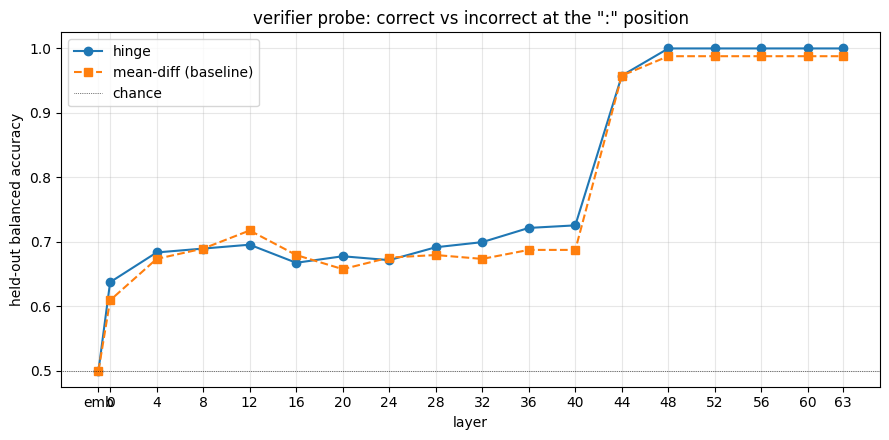

In [11]:
import random
SEED, TEST_FRAC, N_PAIRS = 0, 0.2, 4000
MARGIN, LR, N_STEPS = 0.1, 1e-2, 300
rng = random.Random(SEED)

uniq = sorted(set(tasks.tolist())); rng.shuffle(uniq)
test_tasks = set(uniq[:max(1, int(TEST_FRAC * len(uniq)))])
is_test = np.array([t in test_tasks for t in tasks])
tr_pos = [i for i in range(len(probe_rows)) if labels[i] == 1 and not is_test[i]]
tr_neg = [i for i in range(len(probe_rows)) if labels[i] == 0 and not is_test[i]]
te_pos = [i for i in range(len(probe_rows)) if labels[i] == 1 and is_test[i]]
te_neg = [i for i in range(len(probe_rows)) if labels[i] == 0 and is_test[i]]
print(f"train +{len(tr_pos)}/-{len(tr_neg)}   test +{len(te_pos)}/-{len(te_neg)}  "
      f"({len(test_tasks)}/{len(uniq)} tasks held out)")

def hs_at(i, L): 
    h = probe_hs[i][L].float(); return h / (h.norm() + 1e-9)
def stack(idxs, L): return torch.stack([hs_at(i, L) for i in idxs])
def proj(idxs, v, L): return np.array([(hs_at(i, L) @ v).item() for i in idxs])

def mean_diff(L):
    v = stack(tr_pos, L).mean(0) - stack(tr_neg, L).mean(0)
    return v / (v.norm() + 1e-9)

def optimize_dir(L, device="cuda"):
    pairs = [(rng.choice(tr_pos), rng.choice(tr_neg)) for _ in range(N_PAIRS)]
    diffs = (torch.stack([hs_at(p, L) for p, _ in pairs])
             - torch.stack([hs_at(n, L) for _, n in pairs])).to(device)
    v = (diffs.mean(0) / (diffs.mean(0).norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=LR)
    for _ in range(N_STEPS):
        b = diffs[torch.randint(0, len(diffs), (512,), device=device)]
        vu = v / (v.norm() + 1e-9)
        loss = torch.clamp(MARGIN - (b * vu).sum(-1), min=0).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return (v / (v.norm() + 1e-9)).detach().cpu()

def acc_at(v, L):                         # balanced held-out accuracy (incorrect projects high)
    thr = (proj(tr_pos, v, L).mean() + proj(tr_neg, v, L).mean()) / 2
    return 0.5 * ((proj(te_pos, v, L) > thr).mean() + (proj(te_neg, v, L) <= thr).mean()), thr

rows = []
for L in LAYER_KEYS:
    v_opt, v_md = optimize_dir(L), mean_diff(L)
    a_opt, thr = acc_at(v_opt, L); a_md, _ = acc_at(v_md, L)
    rows.append(dict(layer=L, acc_hinge=a_opt, acc_md=a_md, v_opt=v_opt, v_md=v_md, thr=thr))
    print(f"layer={_llab(L):>3s}  acc_hinge={a_opt:.3f}  acc_md={a_md:.3f}")
sweep = pd.DataFrame(rows)
best = max([r for r in rows if r['layer'] != 'emb'], key=lambda r: r['acc_hinge'])
best_layer, v_best = best['layer'], best['v_opt']
print(f"\nbest layer={_llab(best_layer)}  acc={best['acc_hinge']:.3f}")

# per-error-type generalization at best layer (incorrect-of-type called incorrect)
print("incorrect detection by error type (held-out):")
for et in sorted(set(etypes[te_pos] if len(te_pos) else [])):
    ii = [i for i in te_pos if etypes[i] == et]
    print(f"  {et:14s} {(proj(ii, v_best, best_layer) > best['thr']).mean():.3f}  (n={len(ii)})")

fig, ax = plt.subplots(figsize=(9, 4.5))
xs = [_lx(L) for L in LAYER_KEYS]
ax.plot(xs, sweep['acc_hinge'], 'o-', label='hinge')
ax.plot(xs, sweep['acc_md'], 's--', label='mean-diff (baseline)')
ax.axhline(0.5, color='k', lw=0.5, ls=':', label='chance')
ax.set_xlabel('layer'); ax.set_ylabel('held-out balanced accuracy')
ax.set_title('verifier probe: correct vs incorrect at the ":" position')
ax.set_xticks(xs); ax.set_xticklabels([_llab(L) for L in LAYER_KEYS]); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Validation

**(i)** Mean-diff baseline is the dashed curve in §5. **(iii)** PCA **gif** below: top-2 PCs of the `":"` latent per layer (fixed axes), animated across depth — watch correct/incorrect disentangle (must be linearly separable by the last layer, since logits decode to ` correct`/` incorrect`); saved to `RESULTS/verifier/<model>/verifier_pca.gif`. **(ii)** Apply the verifier direction across every token of a real monolithic condition generation, rendered as a **colored-token heatmap** (`circuitsvis`, red = verifier says incorrect); transition newlines are wrapped in `[[ ]]`. Does the verifier signal track the transition/clock signal? (OOD: the probe was trained in the `(correct vs incorrect)` context.)

In [12]:
# (iii) PCA gif — disentanglement of correct vs incorrect across depth (top-2 PCs per layer)
import matplotlib.animation as animation
from IPython.display import HTML

def _pca2(X):
    Xc = X - X.mean(0)
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    evr = (S ** 2) / (S ** 2).sum()
    return Xc @ Vt[:2].T, evr[:2]

all_idx = list(range(len(probe_rows)))
pca_layers = LAYER_KEYS
pca_results = {}
for L in pca_layers:
    X = np.stack([hs_at(i, L).numpy() for i in all_idx])
    Z2, evr = _pca2(X)
    pca_results[L] = dict(pos=Z2[labels == 1], neg=Z2[labels == 0], evr=evr)

# fixed axis limits across all frames (stable view)
ax_ = np.concatenate([np.concatenate([r['pos'][:, 0], r['neg'][:, 0]]) for r in pca_results.values()])
ay_ = np.concatenate([np.concatenate([r['pos'][:, 1], r['neg'][:, 1]]) for r in pca_results.values()])
px, py = (ax_.max() - ax_.min()) * 0.05, (ay_.max() - ay_.min()) * 0.05
xlim, ylim = (ax_.min() - px, ax_.max() + px), (ay_.min() - py, ay_.max() + py)

fig, ax = plt.subplots(figsize=(7, 6))
neg_sc = ax.scatter([], [], alpha=0.4, s=11, c='tab:green', label='correct (D-)')
pos_sc = ax.scatter([], [], alpha=0.4, s=11, c='tab:red', label='incorrect (D+)')
ax.legend(markerscale=2, loc='upper right'); ax.set_xlim(xlim); ax.set_ylim(ylim)
title = ax.set_title('')

def _update(fi):
    L = pca_layers[fi]; r = pca_results[L]
    pos_sc.set_offsets(r['pos']); neg_sc.set_offsets(r['neg'])
    ax.set_xlabel(f"PC1 ({r['evr'][0]:.1%} var)"); ax.set_ylabel(f"PC2 ({r['evr'][1]:.1%} var)")
    title.set_text(f"layer {_llab(L)} \u2014 verifier latent at ':'  (correct vs incorrect)")
    return pos_sc, neg_sc, title

anim = animation.FuncAnimation(fig, _update, frames=len(pca_layers), interval=400, blit=False)
GIF_DIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, 'verifier', MODEL_SHORT)
os.makedirs(GIF_DIR, exist_ok=True)
gif_path = os.path.join(GIF_DIR, 'verifier_pca.gif')
anim.save(gif_path, writer='pillow', fps=2, dpi=110)
plt.close(fig)
print(f'saved {gif_path}')
HTML(anim.to_jshtml())

2026-06-11 16:14:25 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>
saved /disk/u/arnab/Codes/Projects/goals/results/verifier/Qwen2.5-Coder-32B-Instruct/verifier_pca.gif
2026-06-11 16:14:27 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>


In [13]:
# (ii) verifier direction across a real generation, as a colored-token heatmap (circuitsvis)
from circuitsvis.tokens import colored_tokens
from IPython.display import display
from src.goals.multistep_label import LabeledGeneration

_GLYPH_NL, _GLYPH_TAB, _GLYPH_DOT = '\n\u21b5', '\u21e5', '\u00b7'
def _vis_tok(s):
    s = s.replace('<', '\uff1c').replace('>', '\uff1e')
    s = s.replace('\n', _GLYPH_NL).replace('\r', _GLYPH_NL).replace('\t', _GLYPH_TAB)
    if s.strip() == '' and len(s) > 0:
        s = _GLYPH_DOT * len(s)
    return s

TRANS_MODALITY = 'monolithic'      # transitions are crisp single newlines here
_mdir = os.path.join(CACHE_ROOT, TRANS_MODALITY)
_samples = sorted(s for s in os.listdir(_mdir)
                  if os.path.exists(os.path.join(_mdir, s, 'labels.json'))) if os.path.isdir(_mdir) else []
if not _samples:
    print(f'no condition generations under {_mdir} \u2014 skip (ii)')
else:
    with open(os.path.join(_mdir, _samples[0], 'labels.json')) as f:
        lab = LabeledGeneration.from_dict(json.load(f))
    combined = lab.full_prompt + lab.generation
    inp = prepare_input(prompts=[combined], tokenizer=mt)
    ids = inp['input_ids'][0].tolist()
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    gen_start = next(j for j, (a, b) in enumerate(enc['offset_mapping']) if a >= len(lab.full_prompt) and b > a)
    ly = _lname(best_layer)
    pos = list(range(gen_start, len(ids)))
    hs = get_hs(mt, inp, locations=[(ly, t) for t in pos], return_dict=True)
    scores = []
    for t in pos:
        h = hs[(ly, t)].float().cpu(); h = h / (h.norm() + 1e-9)
        scores.append((h @ v_best).item())
    trans = {st.gen_token_range[1] - 1 for st in lab.labels if st.gen_token_range is not None}
    toks = [_vis_tok(mt.tokenizer.decode([ids[t]])) for t in pos]
    marked = [f'[[{tk}]]' if t in trans else tk for tk, t in zip(toks, pos)]
    print(f"sample={_samples[0]}  ({TRANS_MODALITY})  layer={_llab(best_layer)}   [[..]] = transition newline")
    print(f"verifier proj range [{min(scores):.3f}, {max(scores):.3f}]   "
          f"(red = verifier says INCORRECT, green = correct; probe is OOD here)")
    display(colored_tokens(marked, scores, positive_color='firebrick', negative_color='seagreen'))

sample=cond_0000  (monolithic)  layer=48   [[..]] = transition newline
verifier proj range [-0.159, -0.002]   (red = verifier says INCORRECT, green = correct; probe is OOD here)


## 7. Activation patching — is the verifier signal causal?

Interchange the latent between a **source** and a **destination** prompt whose code differs in correctness, and read the verdict logits at `":"`. Two directions: **correct→incorrect** (cache a correct source, patch into an incorrect dest) and **incorrect→correct**. Pairing requirement: only that the two have *different* correctness (tasks may be arbitrary). Patch the residual stream (`mt.layer_name_format`, Qwen `.output`) at one of two locations and sweep a **(2·`WINDOW_HALF`+1)-layer window** centered over `range(0, n_layer, 4)` (`WINDOW_HALF=0` → single layer). Implemented with `get_hs` (`PatchSpec` list for the layer×token-position patches; read logits at `(mt.lm_head_name, -1)`):

1. **`colon`** — the last token `":"` (window = 1).
2. **`endtag`** — the `</code>` tag span (window = 3 tokens here: `</`,`code`,`>\n\n` — the `>` merges with the trailing newlines, so it's 3 not 5).

Metric: logit of the **source's** verdict token vs the **destination's** verdict token at the readout. Causal ⇒ patching near the layer-44 transition lifts the source-answer logit and drops the dest-answer logit (they cross). Single pair first, then N=50.

In [55]:
import random
from src.tokens import prepare_input, find_token_range
from src.functional import get_hs, PatchSpec

ID_CORRECT = mt.tokenizer(" correct", add_special_tokens=False).input_ids[0]
ID_INCORRECT = mt.tokenizer(" incorrect", add_special_tokens=False).input_ids[0]
ANS = {"correct": ID_CORRECT, "incorrect": ID_INCORRECT}
PATCH_SUFFIX = globals().get(
    "DETECT_SUFFIX", "code>\n\n(correct vs incorrect) The code is:"
)
PATCH_CENTERS = list(range(0, mt.n_layer, 4))
WINDOW_HALF = {
    "colon": 0,
    "endtag": 2,
}  # per-location layer-window half (2*half+1 layers; 0 = single layer)


def vprompt(task, code):
    return build_prompt(task, code) + PATCH_SUFFIX


def _tok_pos(prompt, location):
    """Tokenize prompt; return (inp, positions) for 'colon' (last tok) or 'endtag' (</code> span)."""
    inp = prepare_input(prompts=[prompt], tokenizer=mt, return_offsets_mapping=True)
    offs = inp.pop("offset_mapping")[0]
    if location == "colon":
        positions = [inp["input_ids"].shape[1] - 1]
    else:  # 'endtag' = code-end tag; \n...\n is unique (system tag is " </code> ")
        a, b = find_token_range(
            string=prompt, substring="</code>\n", offset_mapping=offs
        )
        positions = list(range(a + 1, b))

    print(
        f"{positions} => tokens {[mt.tokenizer.decode(t) for t in inp['input_ids'][0, positions].tolist()]})"
    )
    return inp, positions


@torch.no_grad()
def patch_sweep(src_item, dst_item, location, centers=PATCH_CENTERS, half=None):
    """src_item/dst_item = (task, code, correctness). Interchange src->dst residual over a
    (2*half+1)-layer window (half defaults to WINDOW_HALF) at the location's token positions,
    sweeping the window center. Reads verdict logits at ':' via get_hs((lm_head_name, -1))."""
    half = WINDOW_HALF[location] if half is None else half
    print("SOURCE: ", end="")
    s_inp, s_pos = _tok_pos(vprompt(src_item[0], src_item[1]), location)
    print("DESTINATION: ", end="")
    d_inp, d_pos = _tok_pos(vprompt(dst_item[0], dst_item[1]), location)
    # npos = min(len(s_pos), len(d_pos))
    assert len(s_pos) == len(d_pos), "source and destination must have the same number of tokens at the location"
    npos = len(s_pos)
    s_pos, d_pos = s_pos[:npos], d_pos[:npos]
    # cache ALL source residual latents in one forward: {(layer_name, src_pos): vec}
    src_hs = get_hs(
        mt,
        s_inp,
        locations=[(mt.layer_names[l], p) for l in range(mt.n_layer) for p in s_pos],
        return_dict=True,
    )
    base = get_hs(
        mt, d_inp, locations=(mt.lm_head_name, -1)
    )  # unpatched logits (vocab,)
    sa, da = ANS[src_item[2]], ANS[dst_item[2]]
    rows = []
    for c in centers:
        win = [l for l in range(c - half, c + half + 1) if 0 <= l < mt.n_layer]
        patches = [
            PatchSpec(
                location=(mt.layer_names[l], d_pos[k]),
                patch=src_hs[(mt.layer_names[l], s_pos[k])],
                strategy="replace",
            )
            for l in win
            for k in range(npos)
        ]  # layer-window x token-window
        lg = get_hs(mt, d_inp, locations=(mt.lm_head_name, -1), patches=patches)
        rows.append(dict(layer=c, logit_src=lg[sa].item(), logit_dst=lg[da].item()))
    return pd.DataFrame(rows), base[sa].item(), base[da].item()


# sample pools from the validated datasets (correctness-labeled)
_vall = []
for _fn in ["wrong_task.json", "incomplete.json"]:
    with open(os.path.join("..", "..", "data", "verifier", _fn)) as f:
        _vall += json.load(f)
_seen, correct_pool = set(), []
for s in _vall:
    if s["correct"] not in _seen:
        _seen.add(s["correct"])
        correct_pool.append((s["task"], s["correct"], "correct"))
incorrect_pool = [(s["task"], s["incorrect"], "incorrect") for s in _vall]
print(
    f"pools: {len(correct_pool)} correct, {len(incorrect_pool)} incorrect | centers={PATCH_CENTERS}"
)

pools: 254 correct, 442 incorrect | centers=[0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60]


--------------------------------------------------
correct→incorrect
--------------------------------------------------
SOURCE: [150] => tokens [':'])
DESTINATION: [118] => tokens [':'])
SOURCE: [140, 141, 142] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [108, 109, 110] => tokens ['</', 'code', '>\n\n'])
--------------------------------------------------
incorrect→correct
--------------------------------------------------
SOURCE: [118] => tokens [':'])
DESTINATION: [150] => tokens [':'])
SOURCE: [108, 109, 110] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [140, 141, 142] => tokens ['</', 'code', '>\n\n'])


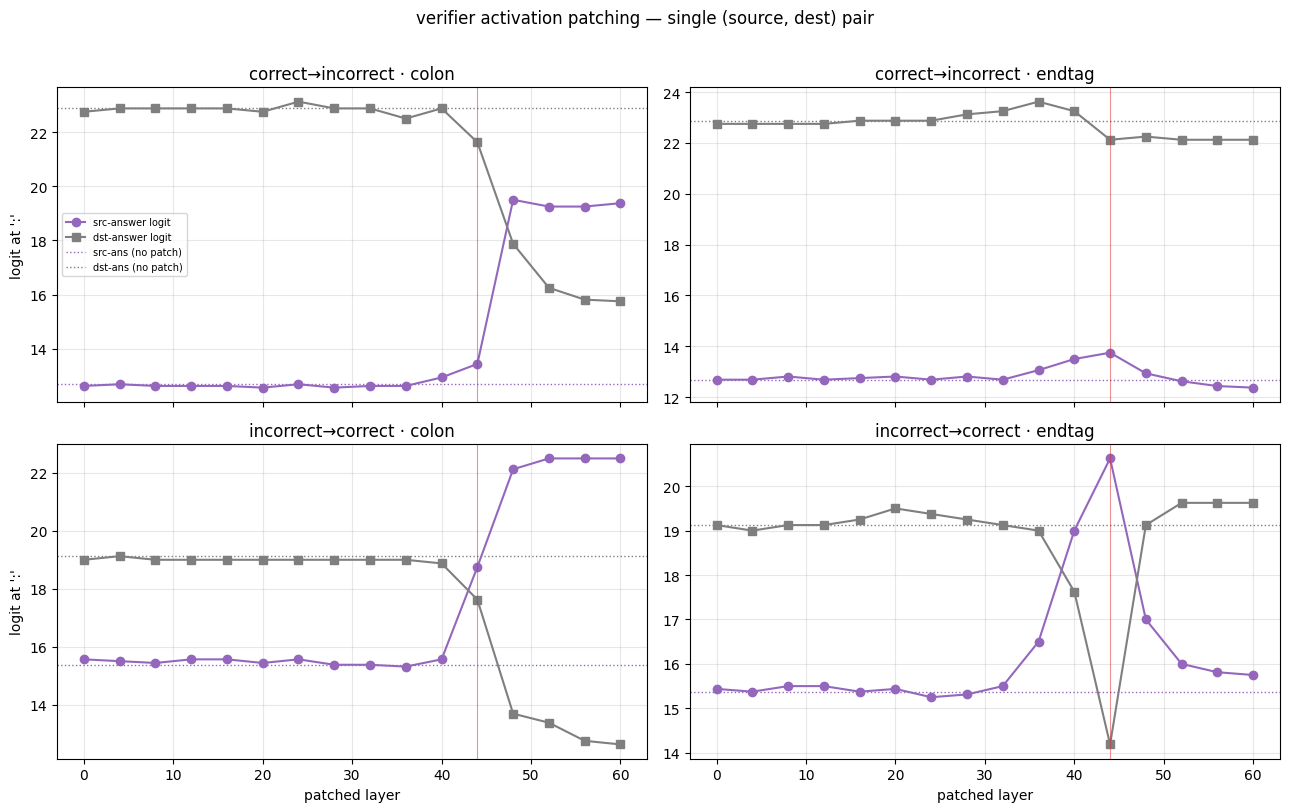

In [57]:
rng7 = random.Random(17)
c_item, i_item = rng7.choice(correct_pool), rng7.choice(incorrect_pool)
DEMOS = {"correct\u2192incorrect": (c_item, i_item), "incorrect\u2192correct": (i_item, c_item)}
LOCS = ["colon", "endtag"]

fig, axes = plt.subplots(len(DEMOS), len(LOCS), figsize=(13, 8), sharex=True)
for ri, (dname, (s, d)) in enumerate(DEMOS.items()):
    print("-" * 50 + "\n" + dname + "\n" + "-" * 50)
    # print(f"src:\n \"{vprompt(s[0], s[1])}\"\n")
    # print(f"dst:\n \"{vprompt(d[0], d[1])}\"\n")
    for ci, loc in enumerate(LOCS):
        df, bs, bd = patch_sweep(s, d, loc)
        ax = axes[ri, ci]
        ax.plot(df.layer, df.logit_src, "o-", color="tab:purple", label="src-answer logit")
        ax.plot(df.layer, df.logit_dst, "s-", color="tab:gray", label="dst-answer logit")
        ax.axhline(bs, color="tab:purple", ls=":", lw=1, label="src-ans (no patch)")
        ax.axhline(bd, color="tab:gray", ls=":", lw=1, label="dst-ans (no patch)")
        ax.axvline(44, color="tab:red", lw=0.8, alpha=0.5)
        ax.set_title(f"{dname} \u00b7 {loc}"); ax.grid(alpha=0.3)
        if ri == len(DEMOS) - 1: ax.set_xlabel("patched layer")
        if ci == 0: ax.set_ylabel("logit at ':'")
axes[0, 0].legend(fontsize=7, loc="best")
fig.suptitle("verifier activation patching \u2014 single (source, dest) pair", y=1.01)
plt.tight_layout(); plt.show()

patch pairs:   0%|          | 0/50 [00:00<?, ?it/s]

SOURCE: [132] => tokens [':'])
DESTINATION: [130] => tokens [':'])
SOURCE: [122, 123, 124] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [120, 121, 122] => tokens ['</', 'code', '>\n\n'])
SOURCE: [130] => tokens [':'])
DESTINATION: [132] => tokens [':'])
SOURCE: [120, 121, 122] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [122, 123, 124] => tokens ['</', 'code', '>\n\n'])
SOURCE: [131] => tokens [':'])
DESTINATION: [132] => tokens [':'])
SOURCE: [121, 122, 123] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [122, 123, 124] => tokens ['</', 'code', '>\n\n'])
SOURCE: [132] => tokens [':'])
DESTINATION: [131] => tokens [':'])
SOURCE: [122, 123, 124] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [121, 122, 123] => tokens ['</', 'code', '>\n\n'])
SOURCE: [98] => tokens [':'])
DESTINATION: [110] => tokens [':'])
SOURCE: [88, 89, 90] => tokens ['</', 'code', '>\n\n'])
DESTINATION: [100, 101, 102] => tokens ['</', 'code', '>\n\n'])
SOURCE: [110] => tokens [':'])
DESTINATION: [98] => to

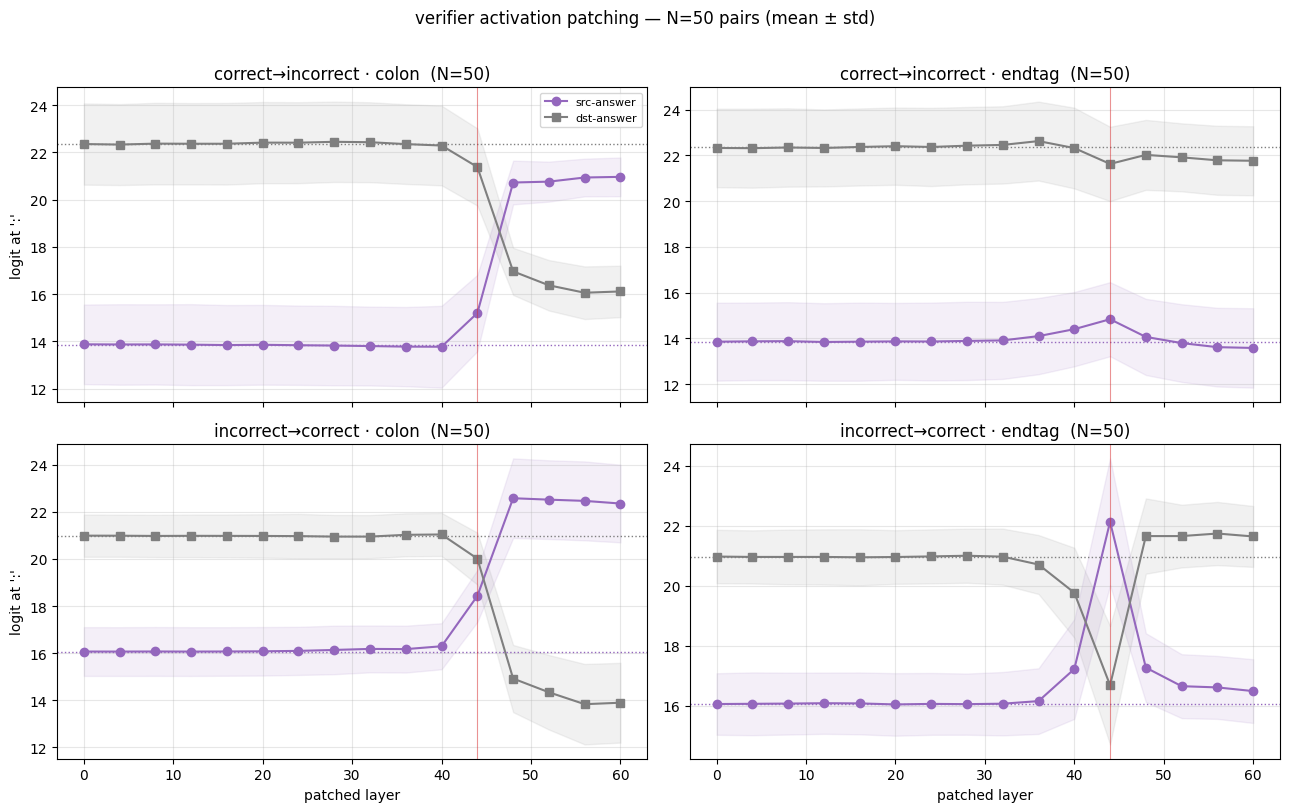

In [58]:
from tqdm.auto import tqdm
### ---- aggregate-sweep config ----
N_PAIRS_PATCH = 50
PATCH_LOCS    = ["colon", "endtag"]    # ~ (1 capture + len(centers) patched + 1 base) forwards per (pair,dir,loc)
### --------------------------------
rngA = random.Random(0)
pairs = [(rngA.choice(correct_pool), rngA.choice(incorrect_pool)) for _ in range(N_PAIRS_PATCH)]
recs = []
for pi, (c, i) in enumerate(tqdm(pairs, desc="patch pairs")):
    for dname, (s, d) in [("correct\u2192incorrect", (c, i)), ("incorrect\u2192correct", (i, c))]:
        for loc in PATCH_LOCS:
            df, bs, bd = patch_sweep(s, d, loc)
            for _, r in df.iterrows():
                recs.append(dict(pair=pi, dir=dname, loc=loc, layer=int(r.layer),
                                 logit_src=r.logit_src, logit_dst=r.logit_dst, base_src=bs, base_dst=bd))
A = pd.DataFrame(recs)

dirs, locs = list(dict.fromkeys(A['dir'])), PATCH_LOCS
fig, axes = plt.subplots(len(dirs), len(locs), figsize=(13, 8), sharex=True)
axes = np.atleast_2d(axes)
for ri, dname in enumerate(dirs):
    for ci, loc in enumerate(locs):
        sub = A[(A['dir'] == dname) & (A['loc'] == loc)]
        g = sub.groupby('layer')
        m_s, e_s = g['logit_src'].mean(), g['logit_src'].std()
        m_d, e_d = g['logit_dst'].mean(), g['logit_dst'].std()
        x = m_s.index.values
        ax = axes[ri, ci]
        ax.plot(x, m_s.values, 'o-', color='tab:purple', label='src-answer')
        ax.fill_between(x, m_s.values - e_s.values, m_s.values + e_s.values, color='tab:purple', alpha=0.1)
        ax.plot(x, m_d.values, 's-', color='tab:gray', label='dst-answer')
        ax.fill_between(x, m_d.values - e_d.values, m_d.values + e_d.values, color='tab:gray', alpha=0.1)
        ax.axhline(sub['base_src'].mean(), color='tab:purple', ls=':', lw=1)
        ax.axhline(sub['base_dst'].mean(), color='tab:gray', ls=':', lw=1)
        ax.axvline(44, color='tab:red', lw=0.8, alpha=0.5)
        ax.set_title(f"{dname} \u00b7 {loc}  (N={N_PAIRS_PATCH})"); ax.grid(alpha=0.3)
        if ri == len(dirs) - 1: ax.set_xlabel('patched layer')
        if ci == 0: ax.set_ylabel("logit at ':'")
axes[0, 0].legend(fontsize=8, loc='best')
fig.suptitle(f"verifier activation patching \u2014 N={N_PAIRS_PATCH} pairs (mean \u00b1 std)", y=1.01)
plt.tight_layout(); plt.show()